# EDA Awal: Data Simulasi MMM Kahf (2025)

Notebook milik: Samuel (Data Scientist). Tujuan: memahami data sebelum menilai model, dan menyiapkan bahan sanity check serta error analysis.

Urutan: setup, ringkasan data, tren dan musiman, efek kalender, pola spend, korelasi, outlier, kesimpulan.

## 0. Setup

In [2]:
!git clone https://github.com/Ricy-Labs/mmm-kahf-indonesia.git
%cd mmm-kahf-indonesia
!git checkout main && git pull

Cloning into 'mmm-kahf-indonesia'...
remote: Enumerating objects: 57, done.
remote: Counting objects: 100% (57/57), done.
remote: Compressing objects: 100% (49/49), done.
remote: Total 57 (delta 14), reused 21 (delta 3), pack-reused 0 (from 0)
Receiving objects: 100% (57/57), 34.19 KiB | 2.28 MiB/s, done.
Resolving deltas: 100% (14/14), done.
/content/mmm-kahf-indonesia/mmm-kahf-indonesia
Already on 'main'
Your branch is up to date with 'origin/main'.
Already up to date.


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data_loader import load_data
from src.config import CHANNEL_COLS, CONTROL_COLS, DATE_COL, TARGET_COL

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

df = load_data()
truth = pd.read_csv("data/processed/true_contributions.csv").set_index("channel")
print(df.shape)

(365, 12)


## 1. Ringkasan data

In [4]:
print("Periode:", df[DATE_COL].min().date(), "sampai", df[DATE_COL].max().date())
print("Jumlah baris:", len(df), "| nilai kosong:", int(df.isna().sum().sum()))
df.describe().T.round(2)

Periode: 2025-01-01 sampai 2025-12-31
Jumlah baris: 365 | nilai kosong: 0


,count,mean,min,25%,50%,75%,max,std
date,365,2025-07-01 23:59:59.999999744,2025-01-01 00:00:00,2025-04-02 00:00:00,2025-07-02 00:00:00,2025-10-01 00:00:00,2025-12-31 00:00:00,NaN
sales,365.0,763.550493,536.23,713.21,745.26,787.94,1158.29,85.837217
influencer_S,365.0,42.508301,4.64,26.02,38.63,54.36,143.15,22.873065
instagram_ads_S,365.0,25.341507,2.62,16.59,23.37,32.21,103.08,12.829204
marketplace_ads_S,365.0,30.57326,2.85,19.29,27.4,37.1,117.21,17.36982
tiktok_ads_S,365.0,15.323534,2.73,9.91,14.26,19.48,46.94,7.744267
offline_activation_S,365.0,2.88989,0.0,0.0,0.0,0.0,114.9,15.869461
ramadan_flag,365.0,0.082192,0.0,0.0,0.0,0.0,1.0,0.275034
harbolnas_flag,365.0,0.019178,0.0,0.0,0.0,0.0,1.0,0.137339
payday_flag,365.0,0.243836,0.0,0.0,0.0,0.0,1.0,0.429984


In [5]:
# Berapa hari tiap flag bernilai 1
flags = ["ramadan_flag", "harbolnas_flag", "payday_flag", "weekend_flag"]
df[flags].sum().rename("jumlah_hari")

,jumlah_hari
ramadan_flag,30
harbolnas_flag,7
payday_flag,89
weekend_flag,104


## 2. Tren dan musiman penjualan

Pertanyaan: apakah penjualan naik sepanjang tahun, dan apakah lonjakan Ramadan dan Harbolnas terlihat?

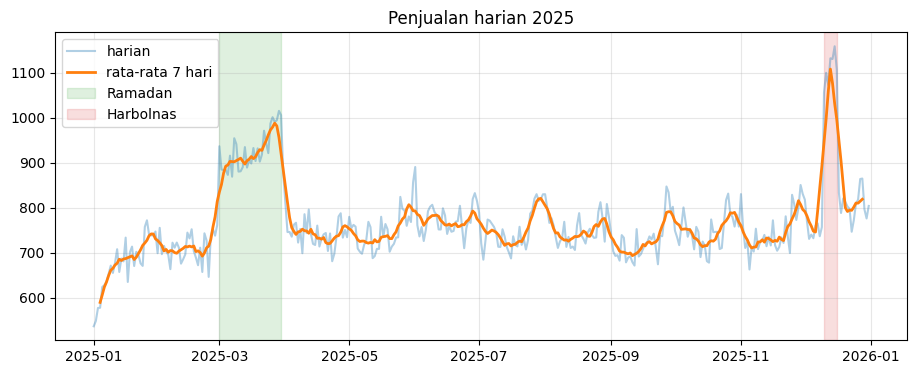

In [6]:
fig, ax = plt.subplots()
ax.plot(df[DATE_COL], df[TARGET_COL], alpha=0.35, label="harian")
ax.plot(df[DATE_COL], df[TARGET_COL].rolling(7, center=True).mean(), lw=2, label="rata-rata 7 hari")
for flag, color, name in [("ramadan_flag", "tab:green", "Ramadan"), ("harbolnas_flag", "tab:red", "Harbolnas")]:
    d = df.loc[df[flag] == 1, DATE_COL]
    ax.axvspan(d.min(), d.max(), color=color, alpha=0.15, label=name)
ax.set_title("Penjualan harian 2025")
ax.legend()
plt.show()

In [7]:
# Tren: bandingkan awal dan akhir tahun (di luar periode musim ramai)
biasa = df[(df.ramadan_flag == 0) & (df.harbolnas_flag == 0)]
bulanan = biasa.groupby(biasa[DATE_COL].dt.to_period("M"))[TARGET_COL].mean().round(1)
print(bulanan)
awal, akhir = df[TARGET_COL].iloc[:30].mean(), df[TARGET_COL].iloc[-30:].mean()
print(f"\nRata-rata 30 hari pertama: {awal:.0f} | 30 hari terakhir: {akhir:.0f} | selisih: {akhir/awal-1:+.1%}")

date
2025-01    674.1
2025-02    711.2
2025-03    877.1
2025-04    742.4
2025-05    746.3
2025-06    774.6
2025-07    749.7
2025-08    751.9
2025-09    726.6
2025-10    746.9
2025-11    745.8
2025-12    787.8
Freq: M, Name: sales, dtype: float64

Rata-rata 30 hari pertama: 673 | 30 hari terakhir: 861 | selisih: +27.9%


## 3. Efek kalender pada penjualan

Bandingkan rata-rata penjualan saat flag aktif vs tidak aktif. Ini hanya perbandingan kasar (belum mengontrol hal lain).

In [8]:
rows = []
for f in flags:
    on, off = df.loc[df[f] == 1, TARGET_COL].mean(), df.loc[df[f] == 0, TARGET_COL].mean()
    rows.append((f, round(on, 1), round(off, 1), f"{on/off-1:+.1%}"))
pd.DataFrame(rows, columns=["flag", "rata2_saat_aktif", "rata2_saat_tidak", "selisih_kasar"])

,flag,rata2_saat_aktif,rata2_saat_tidak,selisih_kasar
0,ramadan_flag,927.6,748.9,+23.9%
1,harbolnas_flag,1107.6,756.8,+46.4%
2,payday_flag,802.2,751.1,+6.8%
3,weekend_flag,789.6,753.2,+4.8%


In [9]:
# Pola hari dalam minggu
df.groupby(df[DATE_COL].dt.day_name())[TARGET_COL].mean().reindex(
    ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]).round(1)

,sales
date,
Monday,757.9
Tuesday,757.4
Wednesday,747.7
Thursday,751.0
Friday,752.0
Saturday,790.1
Sunday,789.2


## 4. Pola spend per channel

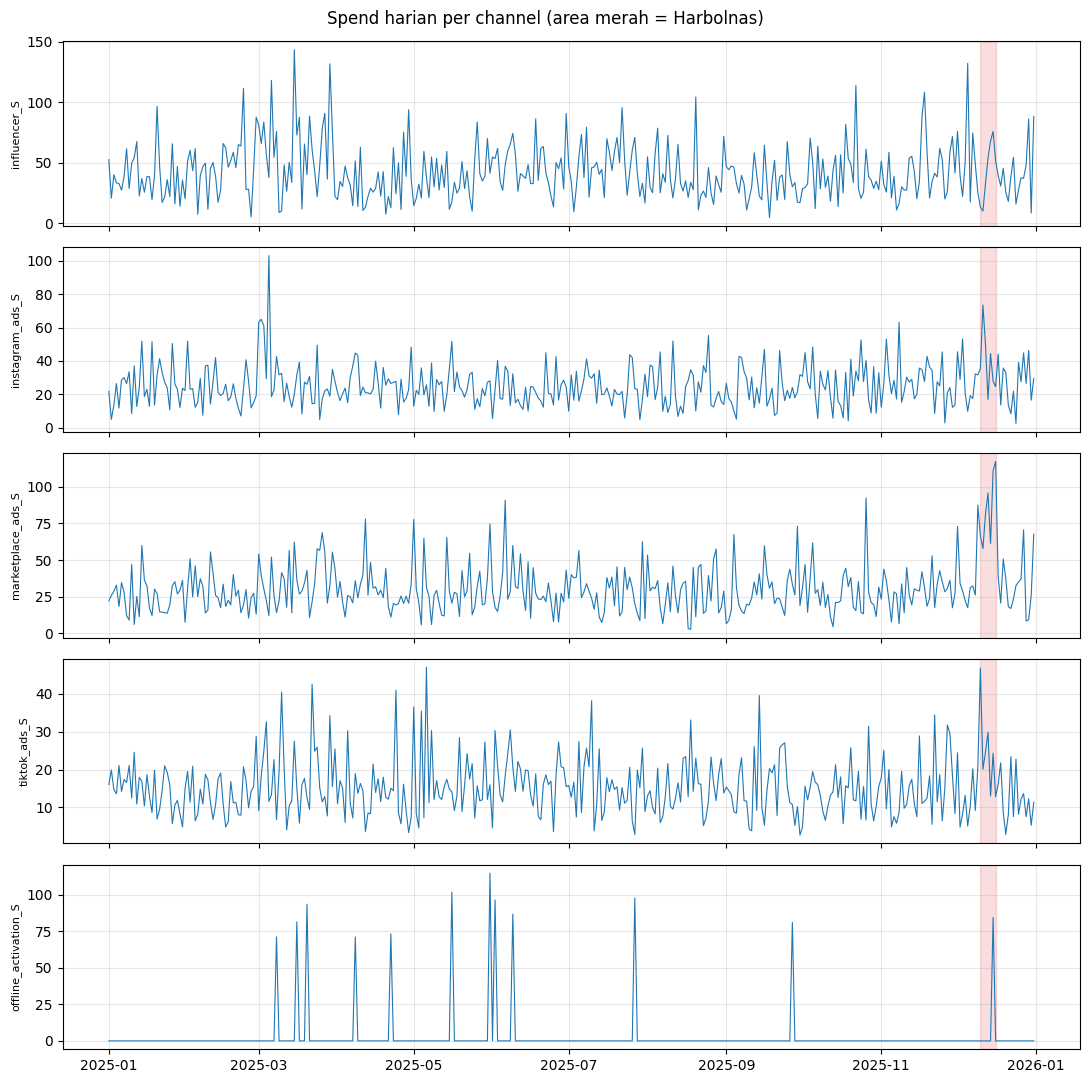

In [10]:
fig, axes = plt.subplots(len(CHANNEL_COLS), 1, figsize=(11, 2.2 * len(CHANNEL_COLS)), sharex=True)
for ax, c in zip(axes, CHANNEL_COLS):
    ax.plot(df[DATE_COL], df[c], lw=0.8)
    d = df.loc[df.harbolnas_flag == 1, DATE_COL]
    ax.axvspan(d.min(), d.max(), color="tab:red", alpha=0.15)
    ax.set_ylabel(c, fontsize=8)
fig.suptitle("Spend harian per channel (area merah = Harbolnas)")
plt.tight_layout()
plt.show()

In [11]:
ringkas = df[CHANNEL_COLS].agg(["mean", "std", "max", "sum"]).T.round(1)
ringkas["porsi_spend"] = (ringkas["sum"] / ringkas["sum"].sum()).round(3)
ringkas["hari_nol"] = (df[CHANNEL_COLS] == 0).sum()
ringkas

,mean,std,max,sum,porsi_spend,hari_nol
influencer_S,42.5,22.9,143.2,15515.5,0.364,0
instagram_ads_S,25.3,12.8,103.1,9249.7,0.217,0
marketplace_ads_S,30.6,17.4,117.2,11159.2,0.262,0
tiktok_ads_S,15.3,7.7,46.9,5593.1,0.131,0
offline_activation_S,2.9,15.9,114.9,1054.8,0.025,353


## 5. Spend vs musim (risiko tercampurnya efek)

Kalau spend sebuah channel melonjak bersamaan dengan flag musim, model sulit memisahkan efek iklan dari efek musim.

In [12]:
rows = []
for c in CHANNEL_COLS:
    har_on, har_off = df.loc[df.harbolnas_flag == 1, c].mean(), df.loc[df.harbolnas_flag == 0, c].mean()
    ram_on, ram_off = df.loc[df.ramadan_flag == 1, c].mean(), df.loc[df.ramadan_flag == 0, c].mean()
    rows.append((c, round(har_on / har_off, 2), round(ram_on / ram_off, 2),
                 round(df[c].corr(df.harbolnas_flag), 2), round(df[c].corr(df.ramadan_flag), 2)))
pd.DataFrame(rows, columns=["channel", "rasio_spend_Harbolnas", "rasio_spend_Ramadan",
                            "korelasi_Harbolnas", "korelasi_Ramadan"]).set_index("channel")

,rasio_spend_Harbolnas,rasio_spend_Ramadan,korelasi_Harbolnas,korelasi_Ramadan
channel,,,,
influencer_S,1.02,1.51,0.01,0.25
instagram_ads_S,1.55,1.24,0.15,0.13
marketplace_ads_S,2.86,1.20,0.43,0.10
tiktok_ads_S,1.62,1.19,0.17,0.10
offline_activation_S,4.46,3.41,0.08,0.10


## 6. Korelasi antar channel dan kontrol

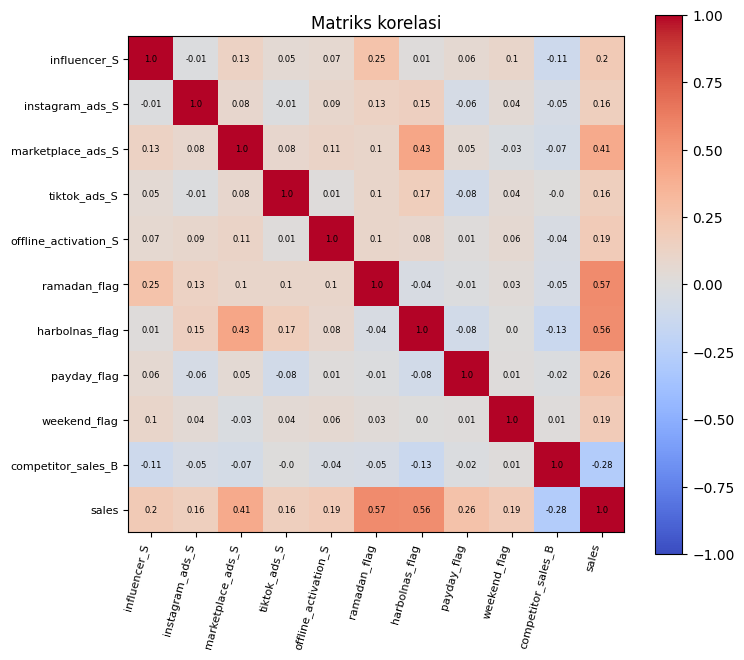

In [13]:
corr = df[CHANNEL_COLS + CONTROL_COLS + [TARGET_COL]].corr().round(2)
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=75, ha="right", fontsize=8)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.index, fontsize=8)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, corr.iloc[i, j], ha="center", va="center", fontsize=6)
ax.grid(False)
fig.colorbar(im)
ax.set_title("Matriks korelasi")
plt.show()

## 7. Pesaing

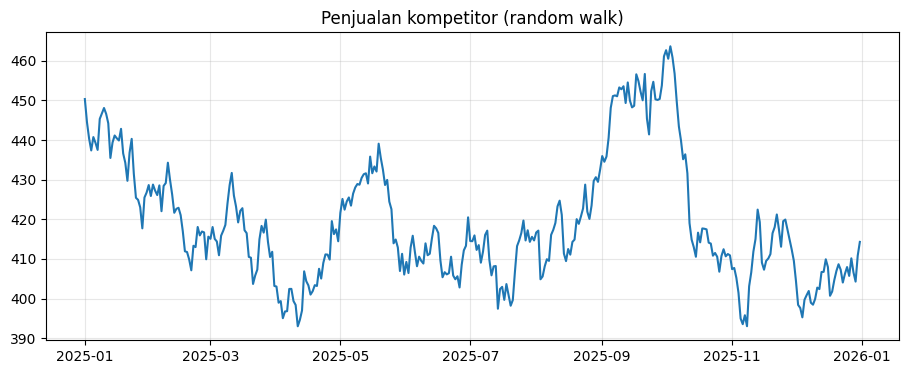

Korelasi kompetitor vs sales: -0.28


In [14]:
fig, ax = plt.subplots()
ax.plot(df[DATE_COL], df["competitor_sales_B"], label="penjualan kompetitor")
ax.set_title("Penjualan kompetitor (random walk)")
plt.show()
print("Korelasi kompetitor vs sales:", round(df["competitor_sales_B"].corr(df[TARGET_COL]), 2))

## 8. Outlier

In [15]:
# Hari dengan penjualan jauh di atas atau di bawah rata-rata bergulir 30 hari
roll = df[TARGET_COL].rolling(30, center=True, min_periods=10)
z = (df[TARGET_COL] - roll.mean()) / roll.std()
out = df.assign(z=z.round(2)).loc[z.abs() > 2.5, [DATE_COL, TARGET_COL, "z"] + flags]
out.sort_values("z", key=abs, ascending=False).head(15)

,date,sales,z,ramadan_flag,harbolnas_flag,payday_flag,weekend_flag
151,2025-06-01,890.11,2.89,0,0,1,1


In [16]:
# Lonjakan spend ekstrem per channel (di atas persentil 99)
for c in CHANNEL_COLS:
    batas = df[c].quantile(0.99)
    hari = df.loc[df[c] > batas, DATE_COL].dt.strftime("%d-%b").tolist()
    print(f"{c}: batas {batas:.0f}, hari: {hari}")

influencer_S: batas 115, hari: ['06-Mar', '15-Mar', '29-Mar', '05-Dec']
instagram_ads_S: batas 63, hari: ['01-Mar', '02-Mar', '05-Mar', '11-Dec']
marketplace_ads_S: batas 91, hari: ['26-Oct', '13-Dec', '15-Dec', '16-Dec']
tiktok_ads_S: batas 41, hari: ['22-Mar', '24-Apr', '06-May', '10-Dec']
offline_activation_S: batas 95, hari: ['16-May', '31-May', '02-Jun', '27-Jul']


## 9. Jawaban benar yang ditanam (untuk acuan sanity check)

In [17]:
truth["share_dari_media"] = (truth.true_contribution_share / truth.true_contribution_share.sum()).round(3)
print("Total share media (benar):", round(truth.true_contribution_share.sum(), 3))
truth.round(3)

Total share media (benar): 0.419


,true_contribution_share,share_dari_media
channel,,
influencer_S,0.124,0.295
instagram_ads_S,0.082,0.197
marketplace_ads_S,0.102,0.244
tiktok_ads_S,0.092,0.218
offline_activation_S,0.019,0.046


## 10. Kesimpulan EDA

- **Tren:** Penjualan naik sepanjang tahun. Rata-rata 30 hari terakhir sekitar
  28% lebih tinggi dari 30 hari pertama (±673 vs ±861). Di luar Ramadan dan
  Harbolnas, rata-rata bulanan bergerak dari ±674 (Jan) ke ±788 (Des).

- **Musiman:** Efek kalender terlihat jelas. Perbandingan kasar (belum
  mengontrol faktor lain): Ramadan +24%, Harbolnas +46%, payday +7%, weekend
  +5%. Sabtu dan Minggu lebih tinggi dari hari kerja (±790 vs ±750).

- **Risiko identifikasi:** Spend marketplace melonjak sekitar 2,9x saat
  Harbolnas dengan korelasi 0,43 terhadap flag Harbolnas, jadi model sulit
  memisahkan efek iklan marketplace dari efek Harbolnas. Spend semua channel
  juga lebih tinggi saat Ramadan (1,2x-1,5x), sehingga efek iklan dan efek
  musim saling tercampur. Korelasi antar channel sendiri rendah, jadi
  multikolinearitas antar channel bukan masalah utama.

- **Pola spend:** Offline activation berbentuk lonjakan: nol di 353 dari 365
  hari, sehingga efeknya sulit diidentifikasi dari sedikit kejadian. Channel
  lain berfluktuasi harian tanpa pola khusus di luar musim ramai.

- **Outlier:** Hampir tidak ada outlier ekstrem. Hanya satu hari (1 Juni) yang
  melewati ambang z > 2,5, dan itu bertepatan dengan payday dan weekend.
  Lonjakan Harbolnas bukan outlier, melainkan efek terencana.

- **Kompetitor:** Penjualan kompetitor berkorelasi negatif lemah dengan
  penjualan kita (-0,28), sejalan dengan efek negatif kecil yang ditanam.

- **Implikasi untuk model:**
  1. Tambahkan komponen tren, karena kenaikan 28% tidak bisa dijelaskan
     seasonality tahunan saja.
  2. Waspadai marketplace saat sanity check: kontribusinya mungkin
     over-credited karena tercampur dengan Harbolnas.
  3. Instagram dan offline kemungkinan sulit diidentifikasi (spend stabil dan
     lonjakan jarang), jadi interval kredibelnya perlu dibaca hati-hati.
  4. Karena ini data simulasi, EDA ini bisa dibandingkan langsung dengan
     asumsi di docs/asumsi.md (Ramadan +20%, Harbolnas +40%, payday +8%,
     weekend +5%): angka kasar di atas konsisten dengan yang ditanam.